# t-SNE

A non-linear way to **look at** high-dimensional data in 2-D. PCA (`34_pca`) preserves large-scale variance and flattens curved structure; t-SNE preserves **who is near whom**, so clusters (like the ten digit classes) separate cleanly.

## How it works

1. **Neighbour probabilities in the original space.** For each point `i`, put a Gaussian over the other points and read off `p(j|i)`. The Gaussian's width is found by binary search so that the distribution has entropy `log(perplexity)` — `perplexity` ≈ effective number of neighbours (try 5–50). Symmetrize: `P = (p(j|i) + p(i|j)) / 2n`.
2. **Neighbour probabilities in the embedding.** `Q[i,j] ∝ 1 / (1 + ‖yᵢ − yⱼ‖²)` — a Student-t (heavy-tailed) kernel. The heavy tail lets moderately-distant points sit very far apart, which fixes the "crowding problem" of squeezing high-dim neighbourhoods into 2-D.
3. **Minimise `KL(P ‖ Q)`** over the 2-D positions by gradient descent:
   `∂KL/∂yᵢ = 4 Σⱼ (pᵢⱼ − qᵢⱼ)(yᵢ − yⱼ) / (1 + ‖yᵢ − yⱼ‖²)`
   with momentum (0.5, then 0.8), per-parameter gains, and **early exaggeration** (`P × 12` for the first 250 steps) so clusters form tight and well apart.

The test checks the gradient against finite differences and that the binary search really hits the requested perplexity. In the demo on 600 digits, KL and trustworthiness match scikit-learn's exact t-SNE (KL 0.377 vs 0.383), while a linear PCA map keeps far fewer neighbours.

## Read the picture carefully

- Cluster **sizes** and **distances between** clusters are not meaningful.
- No `transform()` for new points — it embeds exactly the data you give it.
- Different seeds / perplexities give different pictures. Treat it as exploration, not as features for a model.

`ponytail:` exact version, `O(n²)` per iteration, fine up to a few thousand points. Barnes-Hut or FFT variants are the upgrade for more.

## Usage

```python
# (the class is defined in the Implementation section below)

tsne = TSNE(perplexity=30, n_iter=1000, random_state=0)
Y = tsne.fit_transform(X)      # n x 2
tsne.kl_divergence_            # final objective, lower is better
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


def _sq_dists(X):
    s = (X ** 2).sum(axis=1)
    return np.maximum(s[:, None] + s[None, :] - 2 * X @ X.T, 0.0)


def _conditional_probabilities(d, perplexity):
    """Neighbour distribution of one point given its squared distances `d` to all the others.

    A Gaussian with its own bandwidth beta = 1 / 2 sigma^2, found by binary search so that the
    entropy of the distribution is log(perplexity) -- "perplexity" = effective number of neighbours."""
    target = np.log(perplexity)
    beta, lo, hi = 1.0, 0.0, np.inf
    for _ in range(100):
        p = np.exp(-(d - d.min()) * beta)  # shift by min for numerical stability
        p /= p.sum()
        entropy = -(p * np.log(np.maximum(p, 1e-300))).sum()
        if abs(entropy - target) < 1e-5:
            break
        if entropy > target:   # too flat -> narrow the Gaussian
            lo, beta = beta, beta * 2 if hi == np.inf else (beta + hi) / 2
        else:
            hi, beta = beta, beta / 2 if lo == 0 else (beta + lo) / 2
    return p


def _joint_probabilities(X, perplexity):
    """P[i, j]: how likely i and j are neighbours in the original space (symmetrized, sums to 1)."""
    n = len(X)
    D = _sq_dists(X)
    P = np.zeros((n, n))
    for i in range(n):
        P[i, np.arange(n) != i] = _conditional_probabilities(np.delete(D[i], i), perplexity)
    P = P + P.T
    return P / P.sum()


def _kl_and_grad(Y, P):
    """KL(P || Q) where Q uses a heavy-tailed Student-t kernel in the low-dim space, and its gradient."""
    num = 1.0 / (1.0 + _sq_dists(Y))
    np.fill_diagonal(num, 0.0)
    Q = num / num.sum()
    kl = (P * np.log(np.maximum(P, 1e-12) / np.maximum(Q, 1e-12))).sum()
    W = (P - Q) * num
    grad = 4.0 * (W.sum(axis=1)[:, None] * Y - W @ Y)
    return kl, grad


class TSNE:
    """t-distributed Stochastic Neighbor Embedding (exact version, van der Maaten & Hinton 2008).

    Finds 2-D (or k-D) points whose neighbour structure matches the high-dimensional data:
    1. P = neighbour probabilities in the original space (Gaussians sized by `perplexity`).
    2. Q = neighbour probabilities of the embedding, with a Student-t kernel 1/(1+d^2). Its heavy
       tail lets dissimilar points sit far apart, which fixes the "crowding problem".
    3. Move the points by gradient descent (momentum + per-parameter gains) to minimise KL(P || Q).
       The first `exaggeration_iters` steps multiply P by 12 so clusters form tight and well apart.

    Use it to LOOK at data. Distances between far-apart clusters and cluster sizes are not
    meaningful, there is no transform() for new points, and different seeds give different pictures.

    ponytail: exact O(n^2) per iteration (n up to a few thousand); Barnes-Hut / FFT variants for more."""

    def __init__(self, n_components=2, perplexity=30.0, learning_rate="auto", n_iter=1000,
                 exaggeration=12.0, exaggeration_iters=250, random_state=0):
        self.n_components = n_components
        self.perplexity = perplexity
        self.learning_rate = learning_rate
        self.n_iter = n_iter
        self.exaggeration = exaggeration
        self.exaggeration_iters = exaggeration_iters
        self.random_state = random_state

    def fit_transform(self, X):
        X = np.asarray(X, dtype=float)
        n = len(X)
        P = _joint_probabilities(X, min(self.perplexity, (n - 1) / 3))
        lr = max(n / self.exaggeration / 4, 50) if self.learning_rate == "auto" else self.learning_rate

        rng = np.random.default_rng(self.random_state)
        Y = 1e-4 * rng.standard_normal((n, self.n_components))
        update = np.zeros_like(Y)
        gains = np.ones_like(Y)
        for it in range(self.n_iter):
            early = it < self.exaggeration_iters
            _, grad = _kl_and_grad(Y, P * self.exaggeration if early else P)
            gains = np.maximum(np.where(np.sign(grad) != np.sign(update), gains + 0.2, gains * 0.8), 0.01)
            update = (0.5 if early else 0.8) * update - lr * gains * grad
            Y = Y + update
            Y -= Y.mean(axis=0)

        self.embedding_ = Y
        self.kl_divergence_ = _kl_and_grad(Y, P)[0]
        return Y

    def fit(self, X):
        self.fit_transform(X)
        return self

## See it work

### 1. Digits: PCA vs t-SNE

600 handwritten digits (64 dimensions) squeezed to 2-D. PCA keeps the biggest linear variations and the digits overlap heavily. t-SNE preserves **local neighbourhoods**, and the ten classes separate into distinct islands (the labels were never used).

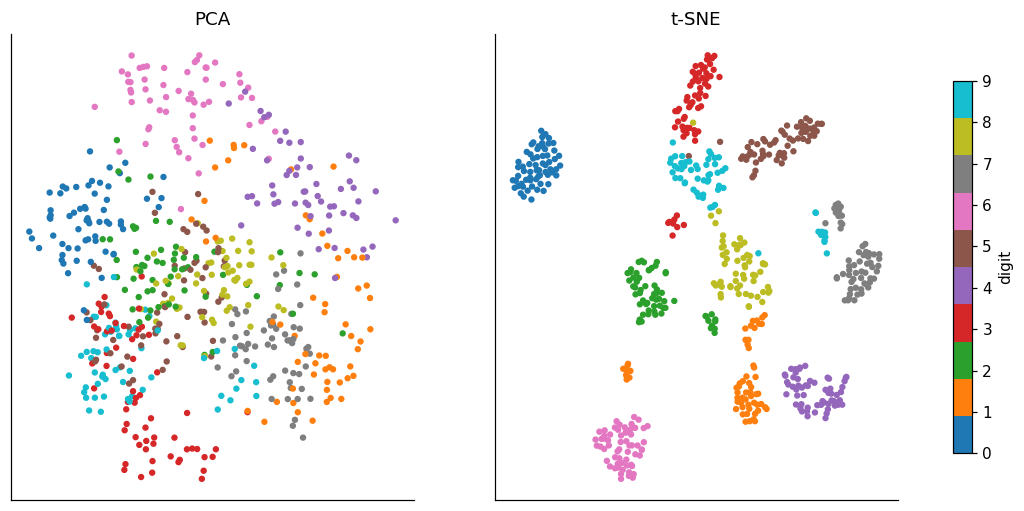

In [3]:
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA as SkPCA

digits = load_digits(); X, y = digits.data[:600], digits.target[:600]
Y = TSNE(perplexity=30, n_iter=750, random_state=0).fit_transform(X)
Zp = SkPCA(2).fit_transform(X)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, Z, n in [(axes[0], Zp, "PCA"), (axes[1], Y, "t-SNE")]:
    sc = ax.scatter(*Z.T, c=y, cmap="tab10", s=10); ax.set_title(n); ax.set_xticks([]); ax.set_yticks([])
plt.colorbar(sc, ax=axes, label="digit", shrink=0.8); plt.show()

### 2. Perplexity: how many neighbours each point cares about

Perplexity is roughly the effective number of neighbours. Small: tiny fragmented clumps. Large: the global structure takes over and clusters blur together. Typical values are 5-50. Same data, three settings:

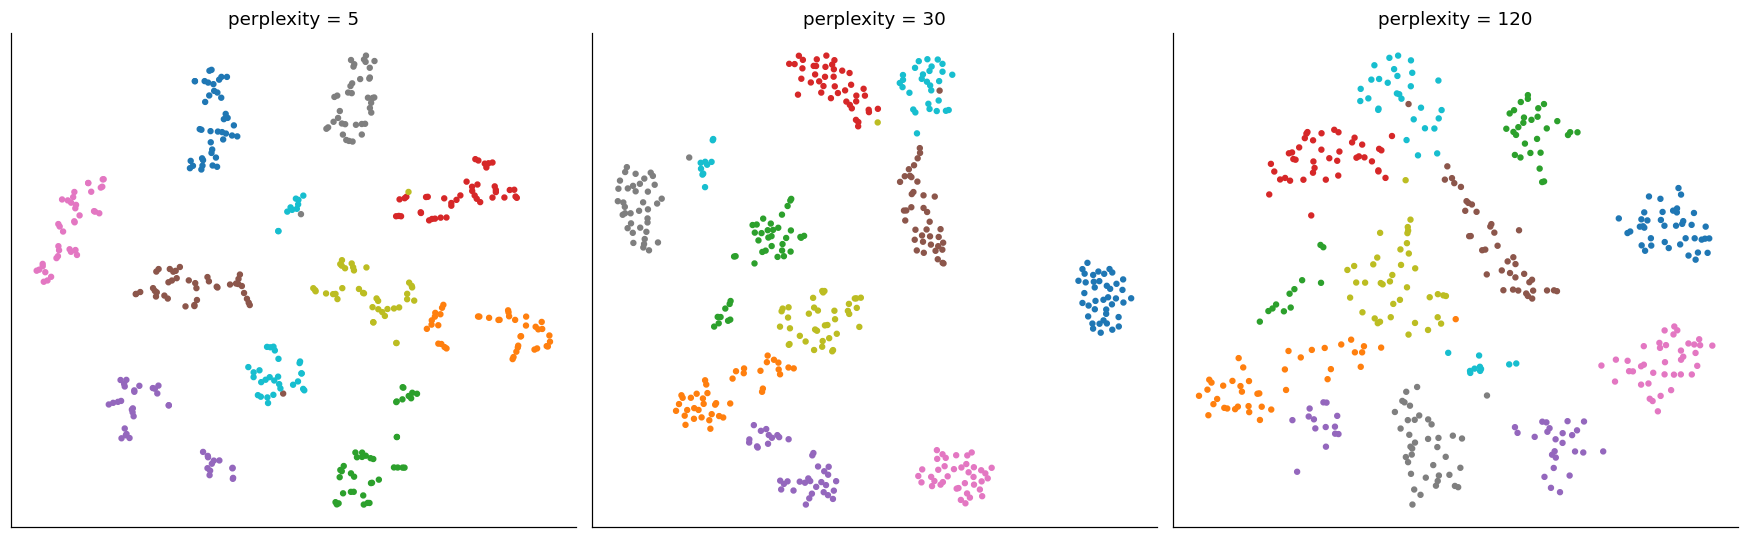

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, p in zip(axes, [5, 30, 120]):
    Yp = TSNE(perplexity=p, n_iter=500, random_state=0).fit_transform(X[:400])
    ax.scatter(*Yp.T, c=y[:400], cmap="tab10", s=10); ax.set_title(f"perplexity = {p}"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### 3. Do not over-read the picture

Different random seeds give different layouts: cluster positions, orientation and distances **between** clusters change, while the neighbourhood structure (which points belong together) stays. Cluster sizes and gaps in a t-SNE plot are not meaningful measurements.

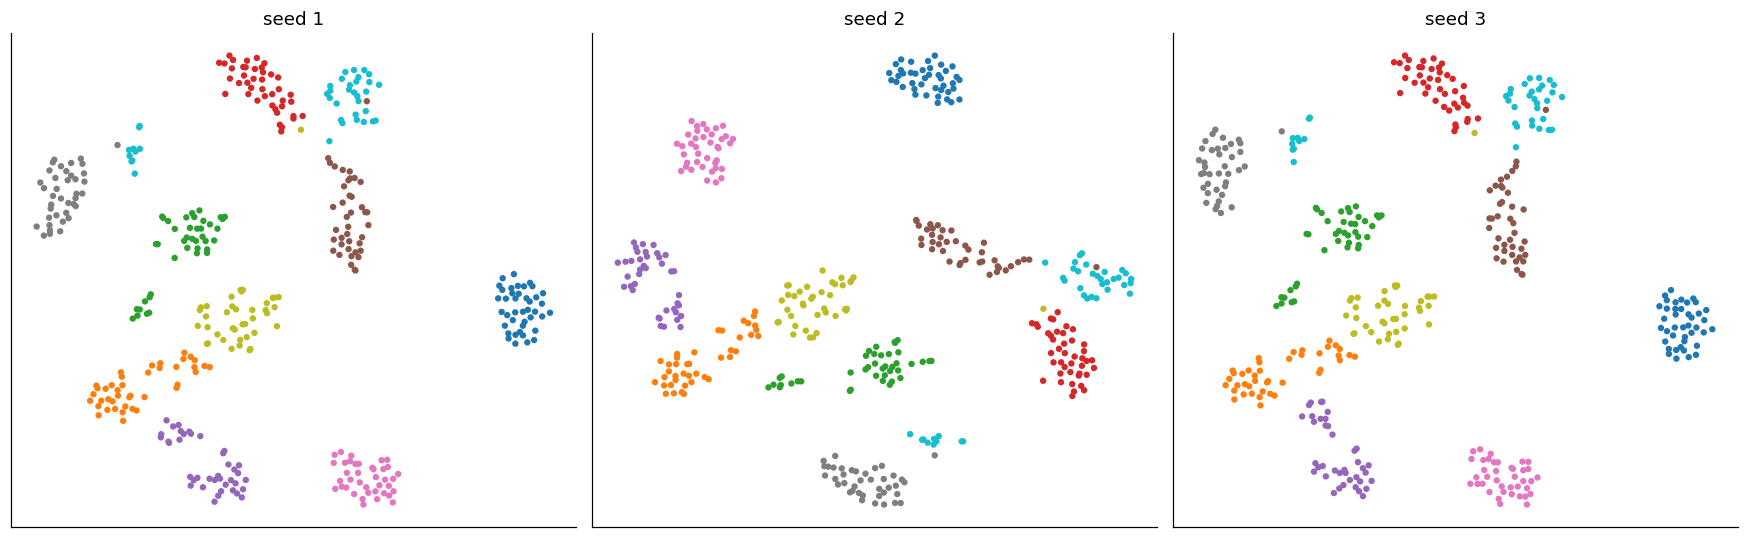

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, seed in zip(axes, [1, 2, 3]):
    Ys = TSNE(perplexity=30, n_iter=500, random_state=seed).fit_transform(X[:400])
    ax.scatter(*Ys.T, c=y[:400], cmap="tab10", s=10); ax.set_title(f"seed {seed}"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE as SklearnTSNE, trustworthiness

digits = load_digits()
X, y = digits.data[:600], digits.target[:600]

ours = TSNE(perplexity=30, n_iter=1000, random_state=0)
Y_ours = ours.fit_transform(X)
sk = SklearnTSNE(perplexity=30, max_iter=1000, init="random", random_state=0, method="exact")
Y_theirs = sk.fit_transform(X)
Y_pca = PCA(2).fit_transform(X)

nearest = lambda Y: (y[np.argsort(((Y[:, None] - Y[None]) ** 2).sum(-1), axis=1)[:, 1]] == y).mean()
print("%-8s %-10s %-24s %s" % ("", "KL", "trustworthiness (k=10)", "1-NN label purity in 2-D"))
print("%-8s %-10.4f %-24.4f %.3f" % ("ours", ours.kl_divergence_, trustworthiness(X, Y_ours, n_neighbors=10), nearest(Y_ours)))
print("%-8s %-10.4f %-24.4f %.3f" % ("sklearn", sk.kl_divergence_, trustworthiness(X, Y_theirs, n_neighbors=10), nearest(Y_theirs)))
print("%-8s %-10s %-24.4f %.3f" % ("PCA", "-", trustworthiness(X, Y_pca, n_neighbors=10), nearest(Y_pca)))

# different random starts -> different pictures, but the quality should be comparable
assert abs(ours.kl_divergence_ - sk.kl_divergence_) < 0.15
assert trustworthiness(X, Y_ours, n_neighbors=10) > 0.97
assert nearest(Y_ours) > 0.9 and nearest(Y_ours) > nearest(Y_pca) + 0.3

         KL         trustworthiness (k=10)   1-NN label purity in 2-D
ours     0.3767     0.9926                   0.988
sklearn  0.3827     0.9923                   0.990
PCA      -          0.8369                   0.573


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def _blobs(seed=0, per=40, dim=10, k=3):
    rng = np.random.default_rng(seed)
    centers = rng.normal(scale=8, size=(k, dim))
    X = np.vstack([c + rng.normal(size=(per, dim)) for c in centers])
    return X, np.repeat(np.arange(k), per)


def test_bandwidth_search_hits_the_requested_perplexity():
    d = np.random.default_rng(0).uniform(0.1, 50, size=99) ** 2
    for perplexity in (5, 15, 30):
        p = _conditional_probabilities(d, perplexity)
        p = p[p > 0]
        assert np.isclose(np.exp(-(p * np.log(p)).sum()), perplexity, rtol=1e-3)


def test_joint_probabilities_are_a_valid_symmetric_distribution():
    X, _ = _blobs()
    P = _joint_probabilities(X, perplexity=15)
    assert np.allclose(P, P.T) and np.isclose(P.sum(), 1.0) and (np.diag(P) == 0).all()
    D = _sq_dists(X)
    assert P[0, np.argsort(D[0])[1]] > P[0, np.argmax(D[0])]   # nearer point -> larger probability


def test_gradient_matches_finite_differences():
    X, _ = _blobs(per=8, k=2)
    P = _joint_probabilities(X, perplexity=5)
    Y = np.random.default_rng(1).normal(size=(len(X), 2))
    _, grad = _kl_and_grad(Y, P)
    numeric = np.zeros_like(Y)
    eps = 1e-6
    for i in range(Y.shape[0]):
        for j in range(Y.shape[1]):
            Yp, Ym = Y.copy(), Y.copy()
            Yp[i, j] += eps
            Ym[i, j] -= eps
            numeric[i, j] = (_kl_and_grad(Yp, P)[0] - _kl_and_grad(Ym, P)[0]) / (2 * eps)
    assert np.abs(grad - numeric).max() < 1e-7


def test_embedding_keeps_clusters_together_and_lowers_kl():
    X, y = _blobs()
    model = TSNE(perplexity=15, n_iter=500, random_state=0)
    Y = model.fit_transform(X)
    assert Y.shape == (len(X), 2)
    nearest = np.argsort(_sq_dists(Y), axis=1)[:, 1]
    assert (y[nearest] == y).mean() > 0.99             # each point's closest embedded neighbour is in its cluster
    random_kl = _kl_and_grad(np.random.default_rng(0).normal(size=Y.shape), _joint_probabilities(X, 15))[0]
    assert model.kl_divergence_ < 0.2 * random_kl      # and the objective really went down

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_bandwidth_search_hits_the_requested_perplexity
PASS test_joint_probabilities_are_a_valid_symmetric_distribution
PASS test_gradient_matches_finite_differences


PASS test_embedding_keeps_clusters_together_and_lowers_kl

all 4 tests passed


## Takeaways

- **Use it** to explore and visualise high-dimensional data (embeddings, single-cell data, image features): it reveals cluster structure that linear methods hide.
- **Method:** neighbour probabilities `P` from Gaussians (width set per point by the perplexity, via binary search), `Q` from a heavy-tailed Student-t in 2-D, gradient descent on `KL(P‖Q)` with early exaggeration and momentum.
- **Pitfalls:** no `transform` for new points; sensitive to perplexity and seed; distances and sizes are not meaningful; `O(n²)` (this exact version), Barnes-Hut or FFT variants scale further. For a transform-able non-linear map see `36_kernel_pca`.
- **Interview line:** *"Match neighbour distributions: Gaussian affinities in the original space, Student-t in the embedding, minimise their KL divergence; the heavy tail fixes the crowding problem."*